# Zero-shot logical inspection from written rules — pushpins probe

**Question:** can an open, on-premises Gemma 4 E4B decide whether a product image obeys a *written* specification,
with **no normal or defective images** to learn from, and beat the published rules-only baseline?

**Baseline to beat (MVTec LOCO, pushpins, rules only):** GPT-4o with chain-of-thought, **59.0% AUROC**
(Fučka & Skočaj, ERK 2025). Their average over all five categories is 69.8%; methods that may see a few
*normal* images reach the high 80s. Pushpins is the baseline's weakest category: it is about counting.

**What this probe tests — two levers, measured separately on the same images:**
1. **Continuous scoring.** The published method outputs a hard yes/no per image. We read the probability Gemma
   assigns to each answer, giving a ranking score. The table shows binary vs continuous on the *same* question.
2. **Question decomposition.** Several small whole-image checks (any empty compartment? any with two pins? count
   per row) instead of one question about the whole spec.
3. **Region decomposition.** The same rule checked on a close-up crop of each of the 15 compartments
   ("how many pushpins are in this compartment?"). Run 1 showed counting across the whole image is the bottleneck.

4. **Rule 3, the box itself.** Error analysis showed the remaining misses had perfect pin counts, so a wall-segment
   check was added: each of the 22 internal walls is cropped and checked ("is there a wall here?"). That failed (the
   model says "wall present" almost everywhere), so the same rule is now checked as counting: two neighbouring
   compartments are cropped together and the model is asked how many compartments it sees (a missing wall gives 1).

**Reusing run 1:** set `RESUME_RUN_ID` to your first run's id; its whole-image answers are kept and only the
compartment questions run.

**Protocol:** only test images are used (good + logical anomalies); no training/validation image is opened.
Our rule text is written from the dataset's published constraints, not copied from the baseline paper (theirs
isn't released), so the comparison is close but not identical.

**Kaggle:** GPU T4 ×2, Internet on, secret `HF_TOKEN` (read access to the private data repo).
Data: MVTec LOCO AD pushpins (CC BY-NC-SA 4.0, © MVTec Software GmbH) from `saiphyohein/builder-cup`.

In [1]:
!pip install -q huggingface_hub

## 0. Config

In [2]:
import os, json, time, datetime, subprocess, base64, io
from pathlib import Path
import numpy as np, pandas as pd, requests

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("work")
os.makedirs(WORK, exist_ok=True)

def get_secret(name):
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return os.environ.get(name)
HF_TOKEN = get_secret("HF_TOKEN")

# ---- model: Gemma 4 E4B (QAT Q4_0) + its vision projector ----
MODEL_REPO  = "google/gemma-4-E4B-it-qat-q4_0-gguf"
MODEL_FILE  = "gemma-4-E4B_q4_0-it.gguf"          # 5.15 GB
MMPROJ_FILE = "gemma-4-E4B-it-mmproj.gguf"        # 0.99 GB vision projector

# ---- serving ----
N_CHAT_PER_GPU = 2          # 2 x (E4B + projector) per T4
CTX_SIZE       = 4096
# --reasoning-budget 0 : switch Gemma's thinking mode off (last run it opened a thought channel on every request)
# --cache-ram 0        : no host-RAM prompt cache (caused the RAM OOM)
EXTRA_ARGS     = ["--reasoning-budget", "0", "--cache-ram", "0"]   # drop a flag if your build rejects it
RECYCLE_EVERY  = 250

# ---- data: MVTec LOCO AD pushpins (CC BY-NC-SA 4.0, (c) MVTec Software GmbH) ----
CATEGORY       = "pushpins"
DATA_REPO      = "saiphyohein/builder-cup"          # private dataset repo -> needs HF_TOKEN with read access
DATA_FILE      = "pushpins.tar.xz"
LOCO_DIR       = None       # or point at an already-extracted copy that contains <category>/test/...
IMAGE_MAX_SIDE = 1024       # downscale before sending to the model

PUSH_TO_HF     = False
HF_REPO        = "saiphyohein/loco-zeroshot"
RESUME_RUN_ID  = None
RUN_ID = RESUME_RUN_ID or datetime.datetime.now().strftime("run%Y%m%d_%H%M%S")
print("WORK:", WORK, "| RUN_ID:", RUN_ID, "| HF token:", bool(HF_TOKEN))


WORK: /kaggle/working | RUN_ID: run20261010_045022 | HF token: True


## 1. llama-server binary

In [3]:
from huggingface_hub import hf_hub_download
BIN_REPO, BIN_FILE = "saiphyohein/llama-cpp-binaries", "llama_cuda_binaries_2026_09_17.tar.gz"
BIN_DIR = f"{WORK}/llama_bin"

def find_llama_server(root):
    for dirpath, _, files in os.walk(root):
        if "llama-server" in files:
            return os.path.join(dirpath, "llama-server")
    return None

LLAMA_SERVER = find_llama_server(BIN_DIR) if os.path.isdir(BIN_DIR) else None
if LLAMA_SERVER is None:
    tar_path = hf_hub_download(BIN_REPO, BIN_FILE, repo_type="dataset", local_dir=f"{WORK}/downloads")
    os.makedirs(BIN_DIR, exist_ok=True)
    subprocess.run(["tar", "-xzf", tar_path, "-C", BIN_DIR], check=True)
    LLAMA_SERVER = find_llama_server(BIN_DIR)
assert LLAMA_SERVER, f"llama-server not found inside {BIN_FILE}"
os.chmod(LLAMA_SERVER, 0o755)
lib_dirs = sorted({d for d, _, fs in os.walk(BIN_DIR) if any(".so" in f for f in fs)})
os.environ["LD_LIBRARY_PATH"] = ":".join(lib_dirs + [os.environ.get("LD_LIBRARY_PATH", "")]).strip(":")
v = subprocess.run([LLAMA_SERVER, "--version"], capture_output=True, text=True, timeout=60)
print("llama-server:", LLAMA_SERVER)
print((v.stdout + v.stderr).strip()[-300:] or f"(exit code {v.returncode})")


llama_cuda_binaries_2026_09_17.tar.gz: reconstructing file:   0%|          |  0.00B / 31.3MB            

llama_cuda_binaries_2026_09_17.tar.gz: downloading bytes:           |  0.00B            

llama-server: /kaggle/working/llama_bin/llama-server
version: 0.4.1-dev (build 11009, commit fb27a525d)
built with GNU 11.4.0 for Linux x86_64


## 2. Model, vision projector, orchestrator

In [4]:
MODEL_PATH  = hf_hub_download(MODEL_REPO, MODEL_FILE, local_dir=f"{WORK}/models")
MMPROJ_PATH = hf_hub_download(MODEL_REPO, MMPROJ_FILE, local_dir=f"{WORK}/models")
print("model:", MODEL_PATH, "\nprojector:", MMPROJ_PATH)

ORCH_URL = "https://raw.githubusercontent.com/sai-phyo-hein/gpu_task_orchestrator/main/gpu_orchestrator.py"
Path(f"{WORK}/gpu_orchestrator.py").write_text(requests.get(ORCH_URL, timeout=60).text)
import sys; sys.path.insert(0, WORK)
from gpu_orchestrator import GPUOrchestrator, OrchestratorConfig, ServerSlot, ThreadedScheduler


gemma-4-E4B_q4_0-it.gguf: reconstructing file:   0%|          |  0.00B / 5.15GB            

gemma-4-E4B_q4_0-it.gguf: downloading bytes:           |  0.00B            

gemma-4-E4B-it-mmproj.gguf: reconstructing file:   0%|          |  0.00B /  992MB            

gemma-4-E4B-it-mmproj.gguf: downloading bytes:           |  0.00B            

model: /kaggle/working/models/gemma-4-E4B_q4_0-it.gguf 
projector: /kaggle/working/models/gemma-4-E4B-it-mmproj.gguf


## 3. Test images (good + logical anomalies only)

pushpins.tar.xz: reconstructing file:   0%|          |  0.00B / 1.12GB            

pushpins.tar.xz: downloading bytes:           |  0.00B            

category folder: /kaggle/working/loco/pushpins
{'good': 138, 'logical_anomalies': 91}


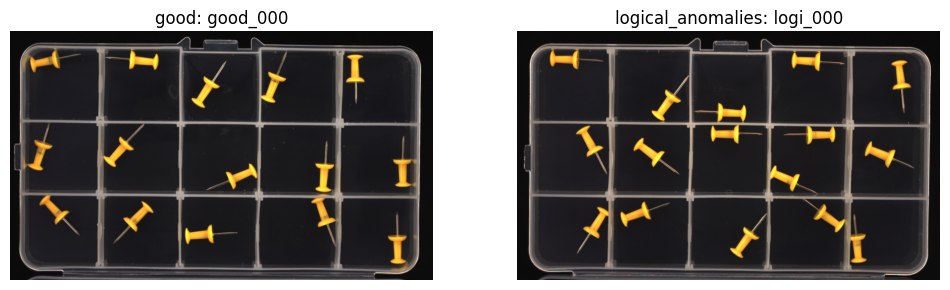

Check the layout matches the rule text below (compartment grid) before running.


In [5]:
from PIL import Image
def find_category_dir(root, category):
    """Locate the folder holding test/good and test/logical_anomalies, wherever the archive put it."""
    candidates = []
    for dirpath, dirnames, _ in os.walk(root):
        if os.path.isdir(os.path.join(dirpath, "test", "good")) and \
           os.path.isdir(os.path.join(dirpath, "test", "logical_anomalies")):
            candidates.append(dirpath)
    named = [c for c in candidates if os.path.basename(c) == category]
    return Path((named or candidates or [None])[0]) if (named or candidates) else None

if LOCO_DIR is None:
    EXTRACT_DIR = f"{WORK}/loco"
    CAT_DIR = find_category_dir(EXTRACT_DIR, CATEGORY) if os.path.isdir(EXTRACT_DIR) else None
    if CAT_DIR is None:
        archive = hf_hub_download(DATA_REPO, DATA_FILE, repo_type="dataset", token=HF_TOKEN,
                                  local_dir=f"{WORK}/downloads")
        os.makedirs(EXTRACT_DIR, exist_ok=True)
        subprocess.run(["tar", "-xJf", archive, "-C", EXTRACT_DIR], check=True)
        CAT_DIR = find_category_dir(EXTRACT_DIR, CATEGORY)
else:
    CAT_DIR = find_category_dir(LOCO_DIR, CATEGORY)
assert CAT_DIR is not None, "no folder with test/good and test/logical_anomalies found in the archive"
print("category folder:", CAT_DIR)

# Zero-shot protocol: only test images are used. No training or validation image is ever opened.
rows = []
for split, label in [("good", 0), ("logical_anomalies", 1)]:
    for p in sorted((CAT_DIR / "test" / split).glob("*.png")):
        rows.append(dict(img_id=f"{split[:4]}_{p.stem}", path=str(p), split=split, label=label))
images = pd.DataFrame(rows)
print(images.split.value_counts().to_dict())

def encode(path, max_side=IMAGE_MAX_SIDE):
    im = Image.open(path).convert("RGB")
    im.thumbnail((max_side, max_side))
    buf = io.BytesIO(); im.save(buf, format="JPEG", quality=92)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, split in zip(axes, ["good", "logical_anomalies"]):
    r = images[images.split == split].iloc[0]
    ax.imshow(Image.open(r.path)); ax.set_title(f"{split}: {r.img_id}"); ax.axis("off")
plt.show()
print("Check the layout matches the rule text below (compartment grid) before running.")


## 4. The written specification and the questions
The spec is the only definition of "normal". The holistic question is the baseline-style check; the others are the
decomposed atomic checks.

In [6]:
# ---- The written specification (the ONLY knowledge of "normal" the system gets) ----
# Layout: confirm from the displayed image. This is fixed camera/product geometry a line engineer knows,
# not something learned from samples. Change ROWS/COLS if the box is laid out differently.
ROWS, COLS = 3, 5
ROW_NAMES = ["top", "middle", "bottom"][:ROWS]

SPEC = (f"The image shows a transparent plastic box with {ROWS * COLS} compartments arranged in {ROWS} rows "
        f"and {COLS} columns. Rules for a correct box:\n"
        f"1. Every compartment must contain exactly one pushpin.\n"
        f"2. So the box must contain exactly {ROWS * COLS} pushpins in total, {COLS} in each row.")

YES_NO = ["yes", "no"]
DIGITS = [str(d) for d in range(10)]

# Each question: text, answer set, and how to turn the answer distribution into P(rule violated).
QUESTIONS = {
    # holistic baseline: one question about the whole spec (closest to the published method, but scored)
    "holistic": dict(text="Does this box satisfy ALL the rules? Answer only Yes or No.",
                     answers=YES_NO, violation=lambda p: p["no"]),
    # decomposed: atomic checks, each easy on its own
    "empty":    dict(text="Is any compartment empty (no pushpin in it)? Answer only Yes or No.",
                     answers=YES_NO, violation=lambda p: p["yes"]),
    "extra":    dict(text="Does any compartment contain two or more pushpins? Answer only Yes or No.",
                     answers=YES_NO, violation=lambda p: p["yes"]),
    **{f"row_{name}": dict(text=f"How many pushpins are in the {name} row of compartments? "
                                f"Answer with a single digit only.",
                           answers=DIGITS, violation=lambda p: 1.0 - p[str(COLS)])
       for name in ROW_NAMES},
}
# Region decomposition: the same rule, checked on a close-up of each compartment (crops come from section 4b).
CELL_TEXT = ("The image is a close-up of a single compartment from a box of pushpins. How many pushpins are "
             "inside this compartment? Count a pushpin if its head is inside the compartment. "
             "Answer with a single digit only.")
for _r in range(ROWS):
    for _c in range(COLS):
        QUESTIONS[f"cell_r{_r}c{_c}"] = dict(text=CELL_TEXT, answers=DIGITS, violation=lambda p: 1.0 - p["1"],
                                             region=(_r, _c))
# Rule 3 (added after error analysis): the box structure itself. Misses had perfect pin counts, so the
# remaining logical errors are in the box, not the pins. Checked per internal wall segment.
WALL_RULE = "3. Every compartment must be separated from each neighbouring compartment by a plastic wall."
WALL_TEXT = ("The image is a close-up of the boundary between two neighbouring compartments of a transparent "
             "plastic box. Is there a plastic wall separating the two compartments here? Answer only Yes or No.")
for _r in range(ROWS):
    for _c in range(COLS - 1):                       # vertical walls between (r,c) and (r,c+1)
        QUESTIONS[f"wall_v_r{_r}c{_c}"] = dict(text=WALL_TEXT, answers=YES_NO, violation=lambda p: p["no"],
                                               wall=("v", _r, _c))
for _r in range(ROWS - 1):
    for _c in range(COLS):                           # horizontal walls between (r,c) and (r+1,c)
        QUESTIONS[f"wall_h_r{_r}c{_c}"] = dict(text=WALL_TEXT, answers=YES_NO, violation=lambda p: p["no"],
                                               wall=("h", _r, _c))
# Rule 3, second attempt: the wall question failed (Gemma said "wall present" almost everywhere), so turn the
# structure check into counting, which the model does well: crop two neighbouring compartments together and ask
# how many compartments it sees. A missing wall merges them into one.
PAIR_TEXT = ("This image shows part of a transparent plastic storage box. How many separate compartments do you "
             "see in this image? Compartments are separated by plastic walls. Answer with a single digit only.")
for _r in range(ROWS):
    for _c in range(COLS - 1):                       # side-by-side pairs
        QUESTIONS[f"pair_h_r{_r}c{_c}"] = dict(text=PAIR_TEXT, answers=DIGITS, violation=lambda p: 1.0 - p["2"],
                                               pair=("h", _r, _c))
for _r in range(ROWS - 1):
    for _c in range(COLS):                           # stacked pairs
        QUESTIONS[f"pair_v_r{_r}c{_c}"] = dict(text=PAIR_TEXT, answers=DIGITS, violation=lambda p: 1.0 - p["2"],
                                               pair=("v", _r, _c))
CELLS = [q for q in QUESTIONS if q.startswith("cell_")]
WALLS = [q for q in QUESTIONS if q.startswith("wall_")]
PAIRS = [q for q in QUESTIONS if q.startswith("pair_")]
DECOMPOSED = [q for q in QUESTIONS if q not in ["holistic", *CELLS, *WALLS, *PAIRS]]
print(SPEC); print("\nwhole-image questions:", ["holistic", *DECOMPOSED]); print("compartment questions:", len(CELLS), "| wall-segment questions:", len(WALLS), "| pair questions:", len(PAIRS))
print("region checks also cover:", WALL_RULE)


The image shows a transparent plastic box with 15 compartments arranged in 3 rows and 5 columns. Rules for a correct box:
1. Every compartment must contain exactly one pushpin.
2. So the box must contain exactly 15 pushpins in total, 5 in each row.

whole-image questions: ['holistic', 'empty', 'extra', 'row_top', 'row_middle', 'row_bottom']
compartment questions: 15 | wall-segment questions: 22 | pair questions: 22
region checks also cover: 3. Every compartment must be separated from each neighbouring compartment by a plastic wall.


## 4b. Compartment grid (for the region checks)
Found from each test image's own wall lines plus the spec's 3 × 5 layout, so no sample is learned from. The plot shows
a few images including the weakest detections; check that the cyan lines sit on the walls.

grid found for 229 images | divider strength min 0.67, median 0.91
weakest: {'logi_019': 0.67, 'logi_023': 0.69, 'logi_022': 0.73} (inspect these below if much lower than the median)


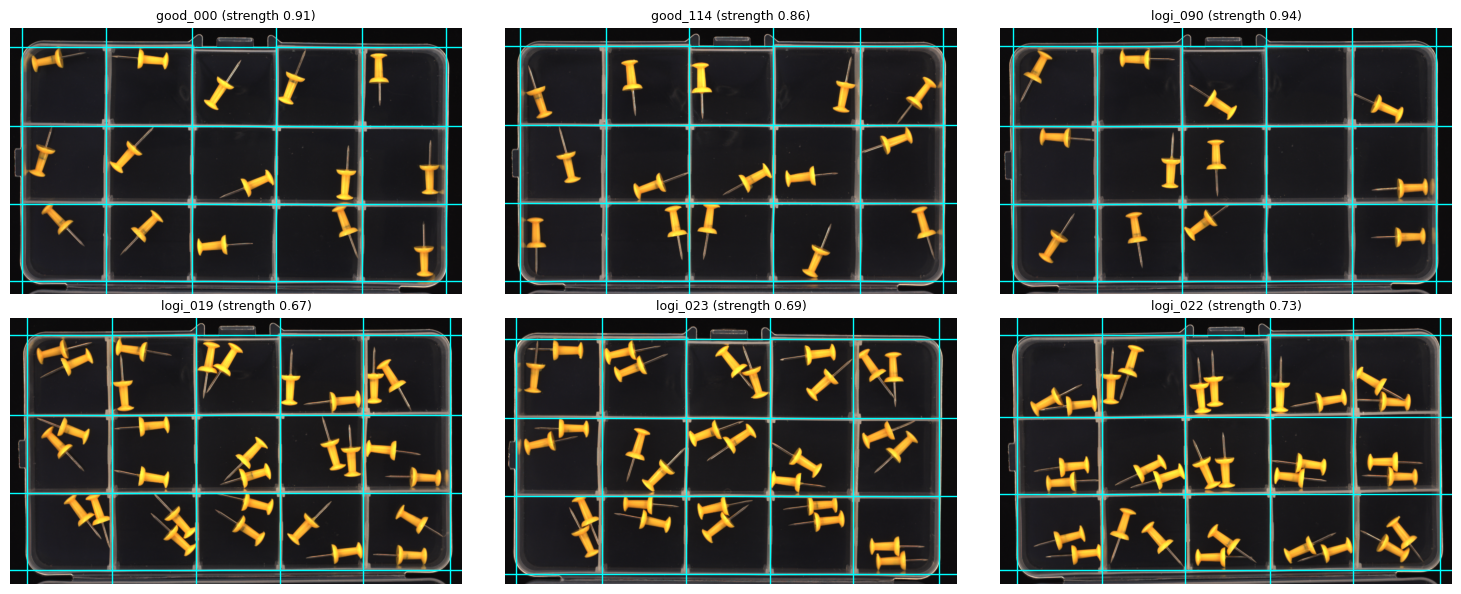

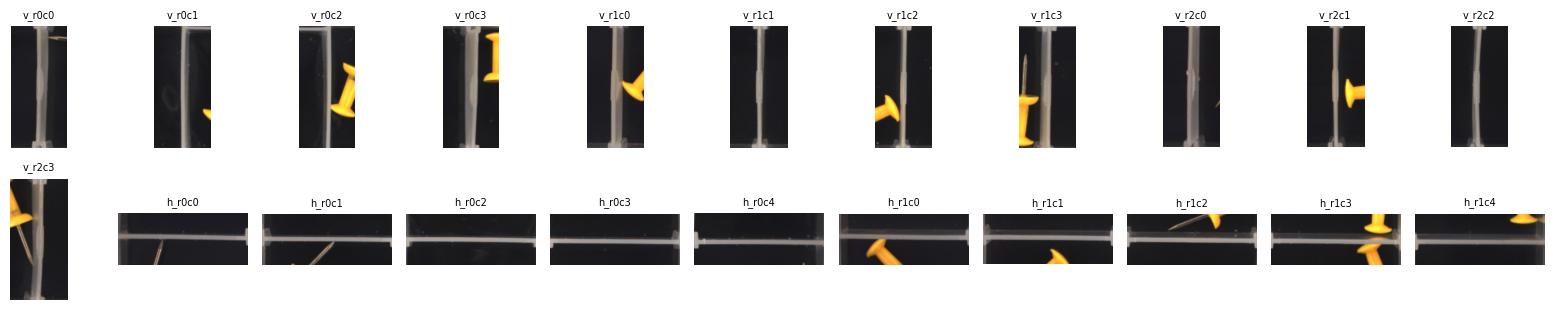

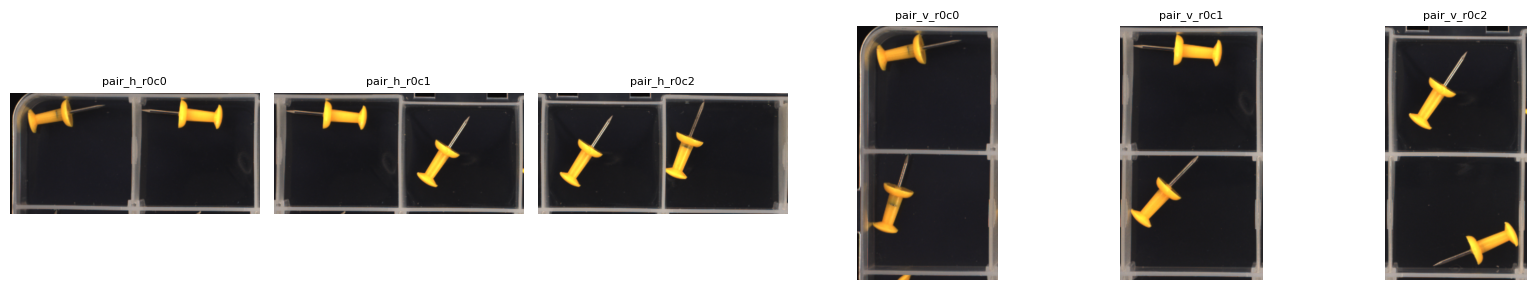

In [7]:
# ---- Compartment grid from the image itself + the spec's layout (ROWS x COLS) ----
# Generic geometry, no learning: compartment walls are bright, low-saturation plastic. Project wall pixels onto
# each axis, take the outermost strong lines as the box border, then look for the (COLS-1) / (ROWS-1) divider
# lines near the evenly spaced positions the spec implies. No normal or anomalous sample is used.
def _smooth(p, k=9):
    return np.convolve(p, np.ones(k) / k, mode="same")

def _peaks(p, thr):
    idx = [i for i in range(1, len(p) - 1) if p[i] >= p[i - 1] and p[i] >= p[i + 1] and p[i] > thr]
    merged = []
    for i in idx:                                            # merge plateaus / near-duplicates
        if merged and i - merged[-1] < 15:
            if p[i] > p[merged[-1]]: merged[-1] = i
        else:
            merged.append(i)
    return merged

def _lines(profile, n_cells, strong=0.3, search=0.25):
    """Try every plausible (outer-left, outer-right) border pair among strong lines near the ends; keep the pair
    whose implied dividers are strongest and whose cells are most evenly sized (rejects lids/hinges/shadows)."""
    p = _smooth(profile)
    pk = _peaks(p, strong * p.max())
    span = pk[-1] - pk[0]
    los = [x for x in pk if x <= pk[0] + 0.25 * span]
    his = [x for x in pk if x >= pk[-1] - 0.25 * span]
    best = None
    for lo in los:
        for hi in his:
            if hi - lo < 0.5 * span:
                continue
            cell = (hi - lo) / n_cells
            inner = []
            for k in range(1, n_cells):
                c = lo + k * cell; w = int(search * cell)
                a, b = int(c - w), int(c + w)
                inner.append(a + int(np.argmax(p[a:b])))
            lines = [lo] + inner + [hi]
            widths = np.diff(lines)
            strength = float(np.mean([p[x] for x in inner]) / (p.max() + 1e-9))
            score = strength - 2.0 * widths.std() / widths.mean()
            if best is None or score > best[0]:
                best = (score, lines, strength)
    return best[1], best[2]

def find_grid(path, rows=ROWS, cols=COLS, sat_max=0.25, val_min=90):
    a = np.asarray(Image.open(path).convert("RGB")).astype(np.float32)
    mx, mn = a.max(-1), a.min(-1)
    wall = (mx > val_min) & ((mx - mn) / (mx + 1e-6) < sat_max)
    xs, sx = _lines(wall.mean(0), cols)
    ys, sy = _lines(wall.mean(1), rows)
    return xs, ys, min(sx, sy)

def cell_boxes(xs, ys, inset=6):
    return [(r, c, (xs[c] + inset, ys[r] + inset, xs[c + 1] - inset, ys[r + 1] - inset))
            for r in range(len(ys) - 1) for c in range(len(xs) - 1)]

def wall_box(xs, ys, orient, r, c, half=0.2, inset=10):
    """Strip centred on one internal wall segment, wide enough to show a bit of both neighbouring compartments."""
    if orient == "v":
        w = half * (xs[c + 1] - xs[c])
        return (int(xs[c + 1] - w), ys[r] + inset, int(xs[c + 1] + w), ys[r + 1] - inset)
    h = half * (ys[r + 1] - ys[r])
    return (xs[c] + inset, int(ys[r + 1] - h), xs[c + 1] - inset, int(ys[r + 1] + h))

def pair_box(xs, ys, orient, r, c, pad=12, size=None):
    """Two neighbouring compartments together, padded outward so their outer walls are visible too."""
    if orient == "h":
        box = (xs[c] - pad, ys[r] - pad, xs[c + 2] + pad, ys[r + 1] + pad)
    else:
        box = (xs[c] - pad, ys[r] - pad, xs[c + 1] + pad, ys[r + 2] + pad)
    if size is not None:
        W, H = size; box = (max(0, box[0]), max(0, box[1]), min(W, box[2]), min(H, box[3]))
    return box

def wall_density(img_id, q):
    """Reference structure check without the model: strength of the wall line inside one wall-segment strip."""
    g = GRIDS[img_id]
    a = np.asarray(Image.open(images.set_index("img_id").loc[img_id, "path"]).convert("RGB")
                   .crop(wall_box(g["xs"], g["ys"], *QUESTIONS[q]["wall"]))).astype(np.float32)
    mx, mn = a.max(-1), a.min(-1)
    wall = (mx > 90) & ((mx - mn) / (mx + 1e-6) < 0.25)
    return wall.mean(axis=0 if QUESTIONS[q]["wall"][0] == "v" else 1).max()

GRIDS = {}
for r in images.itertuples():
    xs, ys, s = find_grid(r.path)
    GRIDS[r.img_id] = dict(xs=xs, ys=ys, strength=s)
strengths = pd.Series({k: v["strength"] for k, v in GRIDS.items()})
print(f"grid found for {len(GRIDS)} images | divider strength min {strengths.min():.2f}, median {strengths.median():.2f}")
print("weakest:", strengths.nsmallest(3).round(2).to_dict(), "(inspect these below if much lower than the median)")

def show_grid(img_id, ax):
    g = GRIDS[img_id]; ax.imshow(Image.open(images.set_index("img_id").loc[img_id, "path"]))
    for x in g["xs"]: ax.axvline(x, c="cyan", lw=1)
    for y in g["ys"]: ax.axhline(y, c="cyan", lw=1)
    ax.set_title(f"{img_id} (strength {g['strength']:.2f})", fontsize=9); ax.axis("off")

import matplotlib.pyplot as plt
picks = list(images.img_id.iloc[[0, len(images) // 2, -1]]) + list(strengths.nsmallest(3).index)
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, img_id in zip(axes.ravel(), picks): show_grid(img_id, ax)
plt.tight_layout(); plt.show()

# preview: the 22 wall-segment crops of the first image (each should show one divider wall)
g0 = GRIDS[images.img_id.iloc[0]]; im0 = Image.open(images.path.iloc[0]).convert("RGB")
wq = [q for q in QUESTIONS if q.startswith("wall_")]
fig, axes = plt.subplots(2, 11, figsize=(16, 3.2))
for ax, q in zip(axes.ravel(), wq):
    ax.imshow(im0.crop(wall_box(g0["xs"], g0["ys"], *QUESTIONS[q]["wall"]))); ax.set_title(q[5:], fontsize=7); ax.axis("off")
plt.tight_layout(); plt.show()

# preview: a few compartment-pair crops of the first image (each should show two compartments and the wall between)
pq = [q for q in QUESTIONS if q.startswith("pair_")]
show_pairs = pq[:3] + pq[12:15]
fig, axes = plt.subplots(1, len(show_pairs), figsize=(16, 3))
for ax, q in zip(axes, show_pairs):
    ax.imshow(im0.crop(pair_box(g0["xs"], g0["ys"], *QUESTIONS[q]["pair"], size=im0.size)))
    ax.set_title(q, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()


## 5. Start the Gemma 4 vision servers

In [8]:
def make_vision_args(model_path, mmproj_path, ctx):
    def builder(slot):
        return ["--model", model_path, "--mmproj", mmproj_path, "--n-gpu-layers", "-1",
                "--flash-attn", "on", "--ctx-size", str(ctx), "--parallel", "1", "--jinja", *EXTRA_ARGS]
    return builder

slots, port = [], 8000
for gpu in ["0", "1"]:
    for j in range(N_CHAT_PER_GPU):
        slots.append(ServerSlot(f"gpu{gpu}-{'abcd'[j]}", gpu, port, "chat")); port += 1

RESULT_DIR = f"{WORK}/results_{RUN_ID}"
orchestrator = GPUOrchestrator(
    config=OrchestratorConfig(llama_server=LLAMA_SERVER, log_dir=f"{WORK}/server_logs",
                              result_dir=RESULT_DIR, health_timeout=600, checkpoint_every=RECYCLE_EVERY),
    slots=slots,
    chat_args=make_vision_args(MODEL_PATH, MMPROJ_PATH, CTX_SIZE),
)
orchestrator.start_all()


Launching gpu0-a: GPU 0, port 8000, kind=chat; free VRAM before=14912 MiB
  gpu0-a ready; free VRAM after=10721 MiB
Launching gpu0-b: GPU 0, port 8001, kind=chat; free VRAM before=10721 MiB
  gpu0-b ready; free VRAM after=6533 MiB
Launching gpu1-a: GPU 1, port 8002, kind=chat; free VRAM before=14912 MiB
  gpu1-a ready; free VRAM after=10721 MiB
Launching gpu1-b: GPU 1, port 8003, kind=chat; free VRAM before=10721 MiB
  gpu1-b ready; free VRAM after=6533 MiB
[servers]
  gpu0-a: GPU 0, port 8000, chat, running
  gpu0-b: GPU 0, port 8001, chat, running
  gpu1-a: GPU 1, port 8002, chat, running
  gpu1-b: GPU 1, port 8003, chat, running


## 6. Request handler + smoke test
Thinking is disabled two ways (server flag and per-request template switch). The parser takes the first generated token
that is a valid answer and renormalises over the answer set. **Check the smoke test:** `first` should be an answer
token (Yes/No or a digit), not `<|channel>`.

In [9]:
SYSTEM = "You are a meticulous quality inspector on a packaging line. Look carefully at the image before answering."
IMG_CACHE = {}
PATHS = images.set_index("img_id").path.to_dict()
def image_url(img_id, qid):
    q = QUESTIONS[qid]
    if "pair" in q:                                            # two neighbouring compartments
        g = GRIDS[img_id]
        im = Image.open(PATHS[img_id]).convert("RGB")
        im = im.crop(pair_box(g["xs"], g["ys"], *q["pair"], size=im.size))
        buf = io.BytesIO(); im.save(buf, format="JPEG", quality=95)
        return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()
    if "wall" in q:                                            # one internal wall segment
        g = GRIDS[img_id]
        im = Image.open(PATHS[img_id]).convert("RGB").crop(wall_box(g["xs"], g["ys"], *q["wall"]))
        buf = io.BytesIO(); im.save(buf, format="JPEG", quality=95)
        return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()
    if "region" not in q:                                      # whole image (cached)
        if img_id not in IMG_CACHE:
            IMG_CACHE[img_id] = encode(PATHS[img_id])
        return IMG_CACHE[img_id]
    r, c = q["region"]                                         # one compartment, native resolution
    g = GRIDS[img_id]
    box = dict(((rr, cc), b) for rr, cc, b in cell_boxes(g["xs"], g["ys"]))[(r, c)]
    im = Image.open(PATHS[img_id]).convert("RGB").crop(box)
    buf = io.BytesIO(); im.save(buf, format="JPEG", quality=95)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()

def answer_distribution(choice, answers):
    """First generated token that is a valid answer -> renormalised distribution over the answer set.
    Variants like 'Yes', ' yes' are merged. Returns (probs dict, position) or (None, None)."""
    aset = set(answers)
    for pos, step in enumerate((choice.get("logprobs") or {}).get("content") or []):
        if step["token"].strip().lower() in aset:
            lp = {}
            for t in step.get("top_logprobs", []):
                a = t["token"].strip().lower()
                if a in aset:
                    lp[a] = np.logaddexp(lp[a], t["logprob"]) if a in lp else t["logprob"]
            floor = min(lp.values()) - 2.0
            raw = np.array([lp.get(a, floor) for a in answers])
            p = np.exp(raw - raw.max()); p /= p.sum()
            return dict(zip(answers, p.tolist())), pos
    return None, None

task_id = lambda t: f"{t[0]}__{t[1]}"

def task_handler(task, chat_port, gpu, worker_name):
    img_id, qid = task
    q = QUESTIONS[qid]
    body = {"messages": [{"role": "system", "content": SYSTEM},
                         {"role": "user", "content": [
                             {"type": "image_url", "image_url": {"url": image_url(img_id, qid)}},
                             {"type": "text", "text": q["text"] if ("region" in q or "wall" in q or "pair" in q) else SPEC + "\n\n" + q["text"]}]}],
            "max_tokens": 8, "temperature": 0, "logprobs": True, "top_logprobs": 20,
            "chat_template_kwargs": {"enable_thinking": False}}
    r = requests.post(f"http://127.0.0.1:{chat_port}/v1/chat/completions", json=body, timeout=300)
    r.raise_for_status()
    choice = r.json()["choices"][0]
    p, pos = answer_distribution(choice, q["answers"])
    content = (choice.get("logprobs") or {}).get("content") or []
    out = {"img_id": img_id, "qid": qid, "parsed": p is not None, "answer_pos": pos,
           "probs": p, "violation": (q["violation"](p) if p else None),
           "first_token": content[0]["token"] if content else None,
           "text": (choice.get("message") or {}).get("content", "")[:120], "worker": worker_name}
    Path(RESULT_DIR, task_id(task) + ".json").write_text(json.dumps(out))
    return out

# ---- smoke test: one good + one anomalous image ----
for img_id in [images[images.label == 0].img_id.iloc[0], images[images.label == 1].img_id.iloc[0]]:
    print(f"\n{img_id}")
    for qid in ["holistic", *DECOMPOSED]:
        o = task_handler((img_id, qid), slots[0].port, slots[0].gpu, "probe")
        Path(RESULT_DIR, task_id((img_id, qid)) + ".json").unlink()
        top = max(o["probs"], key=o["probs"].get) if o["parsed"] else None
        v = f"{o['violation']:.2f}" if o["parsed"] else "-"
        print(f"  {qid:11} first={o['first_token']!r:10} answer={top!s:4} P(violation)={v}  raw={o['text']!r}")
    counts = np.full((ROWS, COLS), "?", dtype=object)
    for qid in CELLS:
        o = task_handler((img_id, qid), slots[0].port, slots[0].gpu, "probe")
        Path(RESULT_DIR, task_id((img_id, qid)) + ".json").unlink()
        r, c = QUESTIONS[qid]["region"]
        counts[r, c] = max(o["probs"], key=o["probs"].get) if o["parsed"] else "?"
    print("  per-compartment counts (should be all 1 for a good box):")
    for row in counts: print("    " + " ".join(row))
    walls_no = []
    for qid in WALLS:
        o = task_handler((img_id, qid), slots[0].port, slots[0].gpu, "probe")
        Path(RESULT_DIR, task_id((img_id, qid)) + ".json").unlink()
        if o["parsed"] and o["probs"]["no"] > 0.5: walls_no.append(qid[5:])
    print(f"  wall segments judged missing: {walls_no or 'none'} (a good box should have none)")
    pairs_off = []
    for qid in PAIRS:
        o = task_handler((img_id, qid), slots[0].port, slots[0].gpu, "probe")
        Path(RESULT_DIR, task_id((img_id, qid)) + ".json").unlink()
        if o["parsed"]:
            top = max(o["probs"], key=o["probs"].get)
            if top != "2": pairs_off.append(f"{qid[5:]}={top}")
    print(f"  compartment pairs not counted as 2: {pairs_off or 'none'} (a good box should have none)")


good_000
  holistic    first='No'       answer=no   P(violation)=0.99  raw='No'
  empty       first='No'       answer=no   P(violation)=0.02  raw='No'
  extra       first='No'       answer=no   P(violation)=0.03  raw='No'
  row_top     first='5'        answer=5    P(violation)=0.01  raw='5'
  row_middle  first='5'        answer=5    P(violation)=0.01  raw='5'
  row_bottom  first='5'        answer=5    P(violation)=0.05  raw='5'
  per-compartment counts (should be all 1 for a good box):
    1 1 1 1 1
    1 1 1 1 1
    1 1 1 1 1
  wall segments judged missing: none (a good box should have none)
  compartment pairs not counted as 2: ['h_r0c1=4', 'h_r1c1=3', 'h_r1c2=3', 'h_r1c3=3', 'h_r2c0=4', 'h_r2c1=3', 'h_r2c2=4', 'h_r2c3=3', 'v_r0c0=3', 'v_r0c2=4', 'v_r1c1=4', 'v_r1c2=4', 'v_r1c3=4'] (a good box should have none)

logi_000
  holistic    first='No'       answer=no   P(violation)=0.99  raw='No'
  empty       first='No'       answer=no   P(violation)=0.03  raw='No'
  extra       first='N

## 7. Run all images × questions across the servers

In [10]:
import sys, threading, contextlib

def mem_available_gb():
    for line in open("/proc/meminfo"):
        if line.startswith("MemAvailable"):
            return int(line.split()[1]) / 1e6
    return float("nan")

def n_done():
    return len(list(Path(RESULT_DIR).glob("*.json")))

TASKS = [(img_id, qid) for img_id in images.img_id for qid in QUESTIONS]
cell_out, stop = sys.stdout, threading.Event()

def monitor(every=60):
    t0 = time.time()
    while not stop.wait(every):
        cell_out.write(f"[{(time.time()-t0)/60:5.1f} min] {n_done()}/{len(TASKS)} done | "
                       f"RAM available {mem_available_gb():.1f} GB\n"); cell_out.flush()

print(f"run {RUN_ID}: {n_done()} of {len(TASKS)} already done ({len(images)} images x {len(QUESTIONS)} questions)")
t0 = time.time()
threading.Thread(target=monitor, daemon=True).start()
log_path = f"{WORK}/scheduler_{RUN_ID}.log"
try:
    with open(log_path, "a") as log, contextlib.redirect_stdout(log):
        ThreadedScheduler(orchestrator=orchestrator, tasks=TASKS, task_id=task_id,
                          task_handler=task_handler).run()
finally:
    stop.set()
errors = [l for l in open(log_path) if "failed:" in l]
print(f"done: {n_done()}/{len(TASKS)} in {(time.time()-t0)/60:.1f} min | failed tasks in log: {len(errors)}")
for l in errors[:5]: print("  ", l.strip())


run run20261010_045022: 0 of 14885 already done (229 images x 65 questions)
[  1.0 min] 253/14885 done | RAM available 28.5 GB
[  2.0 min] 503/14885 done | RAM available 28.2 GB
[  3.0 min] 723/14885 done | RAM available 27.9 GB
[  4.0 min] 912/14885 done | RAM available 28.0 GB
[  5.0 min] 1104/14885 done | RAM available 28.1 GB
[  6.0 min] 1291/14885 done | RAM available 28.3 GB
[  7.0 min] 1503/14885 done | RAM available 29.0 GB
[  8.0 min] 1753/14885 done | RAM available 28.4 GB
[  9.0 min] 2003/14885 done | RAM available 28.0 GB
[ 10.0 min] 2193/14885 done | RAM available 28.0 GB
[ 11.0 min] 2380/14885 done | RAM available 28.0 GB
[ 12.0 min] 2565/14885 done | RAM available 28.1 GB
[ 13.0 min] 2753/14885 done | RAM available 28.6 GB
[ 14.0 min] 3003/14885 done | RAM available 28.7 GB
[ 15.0 min] 3253/14885 done | RAM available 28.2 GB
[ 16.0 min] 3464/14885 done | RAM available 28.0 GB
[ 17.0 min] 3652/14885 done | RAM available 28.0 GB
[ 18.0 min] 3839/14885 done | RAM available 

## 8. Results

In [11]:
from sklearn.metrics import roc_auc_score
res = pd.DataFrame([json.loads(p.read_text()) for p in Path(RESULT_DIR).glob("*.json")])
print("parse rate by question:", res.groupby("qid").parsed.mean().round(3).to_dict())

V = res.pivot(index="img_id", columns="qid", values="violation").astype(float)
V = V.join(images.set_index("img_id")[["label"]])
y_true = V.label.values

def noisy_or(M):
    """Rank-equivalent to 1 - prod(1 - v), computed in log space so 15+ checks don't saturate at 1.0."""
    return -np.log(np.clip(1 - M, 1e-12, 1)).sum(axis=1)

def auroc(score):
    m = ~np.isnan(score)
    return roc_auc_score(y_true[m], score[m]) * 100

rows = []
for qid in ["holistic", *DECOMPOSED]:
    rows.append(dict(method=f"single question: {qid}", auroc=auroc(V[qid].values)))
# Lever 1: continuous score vs. a hard yes/no verdict, same model, same question
rows.append(dict(method="holistic, binary verdict (like published method)",
                 auroc=auroc((V["holistic"].values > 0.5).astype(float))))
rows.append(dict(method="holistic, continuous score", auroc=auroc(V["holistic"].values)))
# Lever 2: decomposition into atomic checks, combined
D = V[DECOMPOSED].fillna(0.0).values
rows.append(dict(method="decomposed, noisy-OR of all checks", auroc=auroc(noisy_or(D))))
rows.append(dict(method="decomposed, max over checks", auroc=auroc(D.max(axis=1))))
# Lever 3: region decomposition, one question per compartment crop
C = V[CELLS].fillna(0.0).values
rows.append(dict(method="regions: noisy-OR over 15 compartments", auroc=auroc(noisy_or(C))))
rows.append(dict(method="regions: max over compartments", auroc=auroc(C.max(axis=1))))
P = res[res.qid.isin(CELLS) & res.parsed].copy()
P["exp_count"] = [sum(int(d) * p for d, p in pr.items()) for pr in P.probs]
dev = P.groupby("img_id").exp_count.sum().sub(ROWS * COLS).abs().reindex(V.index)
rows.append(dict(method="regions: |expected total - 15|", auroc=auroc(dev.values)))
# Rule 3: wall segments
Wl = V[WALLS].fillna(0.0).values
rows.append(dict(method="walls: noisy-OR over 22 wall segments", auroc=auroc(noisy_or(Wl))))
CW = np.concatenate([C, Wl], axis=1)
rows.append(dict(method="regions + walls: max over all region checks", auroc=auroc(CW.max(axis=1))))
rows.append(dict(method="regions + walls: noisy-OR", auroc=auroc(noisy_or(CW))))
rows.append(dict(method="all checks: noisy-OR (whole-image + regions + walls)",
                 auroc=auroc(noisy_or(np.concatenate([D, CW], axis=1)))))
# Rule 3 as counting: compartment pairs (model only; same probability scale as the compartment checks)
Pp = V[PAIRS].fillna(0.0).values
rows.append(dict(method="pairs: max over 22 compartment pairs", auroc=auroc(Pp.max(axis=1))))
rows.append(dict(method="pairs: noisy-OR", auroc=auroc(noisy_or(Pp))))
CP = np.concatenate([C, Pp], axis=1)
rows.append(dict(method="compartments + pairs: max (model only)", auroc=auroc(CP.max(axis=1))))
rows.append(dict(method="compartments + pairs: noisy-OR (model only)", auroc=auroc(noisy_or(CP))))
# Reference: structure checked by pixel geometry instead of the model (combined via label-free rank scaling)
from scipy.stats import rankdata
pct = lambda s: rankdata(s) / len(s)
geo = np.array([1 - min(wall_density(i, q) for q in WALLS) for i in V.index])
rows.append(dict(method="reference: compartments + pixel walls (rank max)",
                 auroc=auroc(np.maximum(pct(C.max(axis=1)), pct(geo)))))
table = pd.DataFrame(rows).round(1)

REF = {"GPT-4o + CoT, rules only (published, pushpins)": 59.0}
print(f"\n{len(V)} images ({int(y_true.sum())} logical anomalies, {int((1 - y_true).sum())} good)")
table


parse rate by question: {'cell_r0c0': 1.0, 'cell_r0c1': 1.0, 'cell_r0c2': 1.0, 'cell_r0c3': 1.0, 'cell_r0c4': 1.0, 'cell_r1c0': 1.0, 'cell_r1c1': 1.0, 'cell_r1c2': 1.0, 'cell_r1c3': 1.0, 'cell_r1c4': 1.0, 'cell_r2c0': 1.0, 'cell_r2c1': 1.0, 'cell_r2c2': 1.0, 'cell_r2c3': 1.0, 'cell_r2c4': 1.0, 'empty': 1.0, 'extra': 1.0, 'holistic': 1.0, 'pair_h_r0c0': 1.0, 'pair_h_r0c1': 1.0, 'pair_h_r0c2': 1.0, 'pair_h_r0c3': 1.0, 'pair_h_r1c0': 1.0, 'pair_h_r1c1': 1.0, 'pair_h_r1c2': 1.0, 'pair_h_r1c3': 1.0, 'pair_h_r2c0': 1.0, 'pair_h_r2c1': 1.0, 'pair_h_r2c2': 1.0, 'pair_h_r2c3': 1.0, 'pair_v_r0c0': 1.0, 'pair_v_r0c1': 1.0, 'pair_v_r0c2': 1.0, 'pair_v_r0c3': 1.0, 'pair_v_r0c4': 1.0, 'pair_v_r1c0': 1.0, 'pair_v_r1c1': 1.0, 'pair_v_r1c2': 1.0, 'pair_v_r1c3': 1.0, 'pair_v_r1c4': 1.0, 'row_bottom': 1.0, 'row_middle': 1.0, 'row_top': 1.0, 'wall_h_r0c0': 1.0, 'wall_h_r0c1': 1.0, 'wall_h_r0c2': 1.0, 'wall_h_r0c3': 1.0, 'wall_h_r0c4': 1.0, 'wall_h_r1c0': 1.0, 'wall_h_r1c1': 1.0, 'wall_h_r1c2': 1.0, 'wall_

,method,auroc
0,single question: holistic,54.0
1,single question: empty,56.9
2,single question: extra,59.6
3,single question: row_top,56.4
4,single question: row_middle,56.1
5,single question: row_bottom,52.3
6,"holistic, binary verdict (like published method)",50.0
7,"holistic, continuous score",54.0
8,"decomposed, noisy-OR of all checks",59.5
9,"decomposed, max over checks",58.8


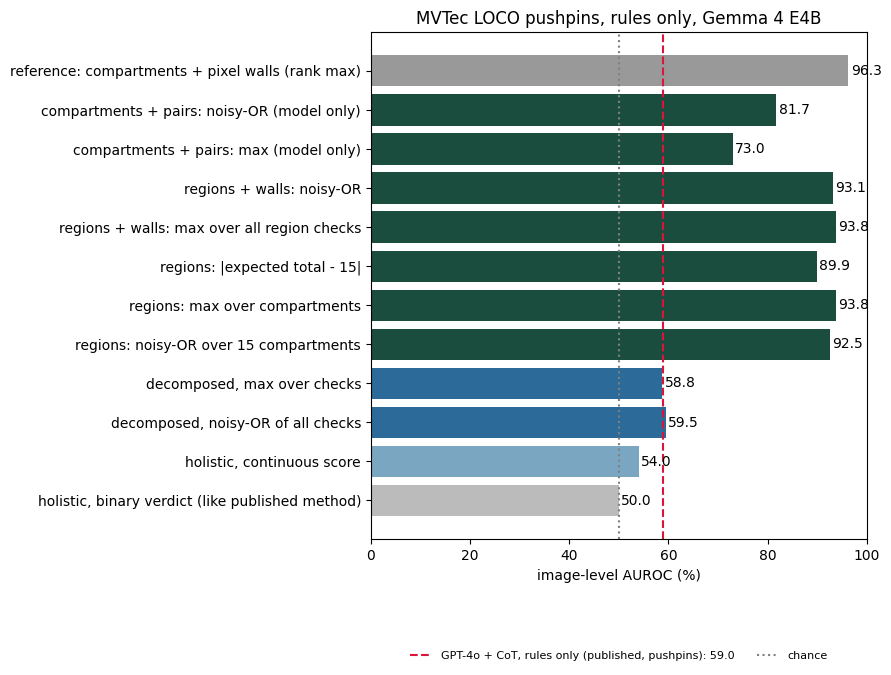

In [12]:
import matplotlib.pyplot as plt
show = table[table.method.str.startswith(("holistic", "decomposed", "regions", "compartments", "reference"))]
colors = ["#bbb" if "binary" in m else "#7aa6c2" if m.startswith("holistic") else
          "#2b6a99" if m.startswith("decomposed") else "#1b4d3e" if m.startswith(("regions", "compartments")) else "#999"
          for m in show.method]
fig, ax = plt.subplots(figsize=(9, 0.45 * len(show) + 1.5))
ax.barh(show.method, show.auroc, color=colors)
for name, val in REF.items():
    ax.axvline(val, ls="--", c="crimson", label=f"{name}: {val}")
ax.axvline(50, ls=":", c="gray", label="chance"); ax.set_xlim(0, 100); ax.set_xlabel("image-level AUROC (%)")
ax.set_title(f"MVTec LOCO {CATEGORY}, rules only, Gemma 4 E4B")
for i, v in enumerate(show.auroc): ax.text(v + 0.5, i, f"{v:.1f}", va="center")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(f"{WORK}/loco_{CATEGORY}_{RUN_ID}.png", dpi=150); plt.show()

table.to_csv(f"{WORK}/loco_{CATEGORY}_{RUN_ID}.csv", index=False)
res.to_json(f"{WORK}/loco_{CATEGORY}_predictions_{RUN_ID}.jsonl", orient="records", lines=True)
if PUSH_TO_HF:
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    api.create_repo(HF_REPO, repo_type="dataset", private=True, exist_ok=True)
    for f in [f"loco_{CATEGORY}_{RUN_ID}.csv", f"loco_{CATEGORY}_predictions_{RUN_ID}.jsonl", f"loco_{CATEGORY}_{RUN_ID}.png"]:
        api.upload_file(path_or_fileobj=f"{WORK}/{f}", path_in_repo=f"runs/{RUN_ID}/{f}",
                        repo_id=HF_REPO, repo_type="dataset")


In [14]:
pp = res[res.qid.isin(PAIRS) & res.parsed].copy()
pp["answer"] = [max(p, key=p.get) for p in pp.probs]
pp["label"] = pp.img_id.map(images.set_index("img_id").label)
print(pp[pp.label == 0].answer.value_counts(normalize=True).round(3).head(5))

answer
2    0.360
3    0.347
4    0.283
6    0.008
5    0.002
Name: proportion, dtype: float64


In [13]:
orchestrator.stop_all()   # free the GPUs

[cleanup] all servers stopped


## Reading the results
- **holistic binary vs holistic continuous** isolates lever 1 (same model, same question, only the scoring differs).
- **decomposed** vs **holistic continuous** isolates lever 2.
- **Per-question rows** show which atomic checks actually carry signal, useful for choosing checks in other categories.
- Compare against the red line (published 59.0). With ~230 images, differences of a few points are within noise;
  look for a clear margin.
- If parse rates are below 1, inspect `res[~res.parsed].text`.